# Module 05 - Re-Identification Embedding Model for Appearance Matching

**Course:** CS 5567 – Deep Learning  **Runtime:** GPU

**Objective.** This notebook adds appearance information to the tracking pipeline. A re-identification (ReID) model maps each pedestrian crop to an embedding vector. Crops of the same person should be close in this space, and crops of different people should be far apart. Appearance can help to reconnect a person after occlusion and to detect when one track contains two different people (the identity switch found in Notebook 04).

**Procedure**
1. Build a ReID dataset from the MOT16 ground-truth boxes. Training and validation identities come from different sequences, so there is no identity leakage.
2. Evaluate an ImageNet ResNet-50 without ReID training (baseline) with mAP and Rank-1/5/10.
3. Train a ResNet-50 with a BNNeck, cross-entropy loss, and batch-hard triplet loss. Checkpoints are saved to Drive.
4. Compare the two models and visualize retrieval results and the embedding space (t-SNE).
5. Use the embeddings to repair the tracker output of Notebook 04: split tracks that contain two people, and merge tracks that belong to one person.
6. Re-evaluate with TrackEval and report the change in IDF1, HOTA, and identity switches.

**Key result.** The tracking metrics before and after appearance-based repair (step 6), and the ReID retrieval quality (step 4).

In [ ]:
TIMING = {}
TIMING['E2_finetuned_botsort'] = run_tracker('E2_finetuned_botsort', WEIGHTS_FT, 'botsort', {}, None)
shutil.copytree(TE_TRACKERS, RESULTS/'tracks_txt', dirs_exist_ok=True)

{'run': 'E2_finetuned_botsort', 'frames': 525, 'rows': 4777, 'pred_ids': 72, 'seconds': 18.2, 'fps': 28.8}


PosixPath('/content/drive/MyDrive/MOT16_project/Backup/results/tracks_txt')

In [ ]:
shutil.copytree(TE_TRACKERS, RESULTS/'tracks_txt', dirs_exist_ok=True)
print(sorted(p.name for p in (RESULTS/'tracks_txt').iterdir()))

['E0_pretrained_bytetrack', 'E1_finetuned_bytetrack', 'E2_finetuned_botsort', 'S_buffer_15', 'S_buffer_30', 'S_buffer_60', 'S_buffer_90', 'S_high_0.25', 'S_high_0.4', 'S_high_0.6']


In [ ]:
# 1. Setup: Drive, packages, paths
from google.colab import drive
drive.mount('/content/drive')
!pip -q install scikit-learn tqdm
from pathlib import Path
import time, shutil, subprocess, sys, random, configparser
import numpy as np, pandas as pd
import cv2, torch, torch.nn as nn, torch.nn.functional as F, torchvision
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

CANDIDATES = [Path('/content/drive/MyDrive/MOT16_project/Backup'),
              Path('/content/drive/MyDrive/MOT16_project'),
              Path('/content/drive/MyDrive/DL_Video_Tracking ')]      # trailing space is intentional
BASE = next((p for p in CANDIDATES if (p/'yolo_mot16_best.pt').exists()), None)
assert BASE, 'yolo_mot16_best.pt not found - run Notebook 03 first'
RESULTS = BASE/'results'; RESULTS.mkdir(exist_ok=True)
MOT_DRIVE = next((p for p in [BASE/'MOT16', BASE.parent/'MOT16', BASE.parent/'Backup'/'MOT16'] if (p/'train').exists()), None)
assert MOT_DRIVE, 'MOT16 folder not found'
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print('BASE:', BASE, '| device:', dev, torch.cuda.get_device_name(0) if dev == 'cuda' else 'SET RUNTIME TO GPU')
random.seed(0); np.random.seed(0); torch.manual_seed(0)

BASE: /content/drive/MyDrive/MOT16_project/Backup | device: cuda NVIDIA A100-SXM4-40GB


In [ ]:
# 2. Configuration (the only cell you normally edit)
SEQ        = 'MOT16-09'                                        # validation sequence (same as Notebook 04)
TRAIN_SEQS = ['MOT16-02', 'MOT16-04', 'MOT16-05', 'MOT16-10', 'MOT16-11', 'MOT16-13']
assert SEQ not in TRAIN_SEQS

# ReID data
STRIDE        = 5       # use every 5th frame (neighbouring frames are almost identical)
MIN_VIS_TRAIN = 0.4     # train on reasonably visible people (random erasing teaches occlusion robustness)
MIN_VIS_EVAL  = 0.4
MAX_PER_ID    = 60      # cap crops per identity so long tracks do not dominate
IMG_H, IMG_W  = 256, 128

# Training
P, K       = 16, 4      # each batch: 16 identities x 4 crops (needed for triplet loss)
EPOCHS     = 12
ITERS      = 200        # batches per epoch
LR         = 3.5e-4
MARGIN     = 0.3
RUN_TRAIN  = True       # False: load reid_best.pt from Drive and skip training

# Local copy of the validation sequence (Drive is slow for many small files)
SEQ_DIR = Path('/content/MOT16')/'train'/SEQ
if not SEQ_DIR.exists():
    SEQ_DIR.parent.mkdir(parents=True, exist_ok=True); shutil.copytree(MOT_DRIVE/'train'/SEQ, SEQ_DIR)
IMG_DIR = SEQ_DIR/'img1'
cp = configparser.ConfigParser(); cp.read(SEQ_DIR/'seqinfo.ini')
FPS_VIDEO = int(cp['Sequence']['frameRate']); N_FRAMES = int(cp['Sequence']['seqLength'])
print(SEQ, 'frames:', N_FRAMES)

MOT16-09 frames: 525


In [ ]:
# 3. Build the ReID crop dataset from MOT16 ground truth (cached on Drive as a zip)
CROP_DIR = Path('/content/reid_crops'); ZIP = BASE/'reid_crops.zip'
GT_COLS = ['frame','id','x','y','w','h','conf','cls','vis']

def extract_crops(seq, min_vis, max_per_id, stride):
    d = MOT_DRIVE/'train'/seq
    gt = pd.read_csv(d/'gt'/'gt.txt', header=None, names=GT_COLS)
    gt = gt[(gt.cls == 1) & (gt.conf == 1) & (gt.vis >= min_vis) & ((gt.frame - 1) % stride == 0) & (gt.h >= 40) & (gt.w >= 16)]
    keep = []
    for pid, g in gt.groupby('id'):
        g = g.sort_values('frame')
        if len(g) > max_per_id:
            g = g.iloc[np.linspace(0, len(g) - 1, max_per_id).astype(int)]    # evenly spaced in time
        keep.append(g)
    gt = pd.concat(keep); rows = []
    for f, g in tqdm(gt.groupby('frame'), desc=seq):
        img = cv2.imread(str(d/'img1'/f'{f:06d}.jpg')); H, W = img.shape[:2]
        for r in g.itertuples():
            x1, y1 = max(int(r.x), 0), max(int(r.y), 0); x2, y2 = min(int(r.x + r.w), W), min(int(r.y + r.h), H)
            if x2 - x1 < 8 or y2 - y1 < 16: continue
            out = CROP_DIR/seq/str(r.id)/f'{f:06d}.jpg'; out.parent.mkdir(parents=True, exist_ok=True)
            cv2.imwrite(str(out), img[y1:y2, x1:x2])
            rows.append(dict(path=str(out), seq=seq, pid=f'{seq}_{r.id}', frame=f, vis=r.vis))
    return pd.DataFrame(rows)

if ZIP.exists() and not CROP_DIR.exists():
    shutil.unpack_archive(str(ZIP), '/content')
if (CROP_DIR/'index.csv').exists():
    index = pd.read_csv(CROP_DIR/'index.csv')
else:
    shutil.rmtree(CROP_DIR, ignore_errors=True)
    index = pd.concat([extract_crops(s, MIN_VIS_TRAIN if s != SEQ else MIN_VIS_EVAL, MAX_PER_ID, STRIDE) for s in TRAIN_SEQS + [SEQ]],
                      ignore_index=True)
    index.to_csv(CROP_DIR/'index.csv', index=False)
    shutil.make_archive(str(ZIP.with_suffix('')), 'zip', '/content', 'reid_crops')     # cache on Drive
train_df = index[index.seq.isin(TRAIN_SEQS)].reset_index(drop=True)
val_df   = index[index.seq == SEQ].reset_index(drop=True)
label_map = {p: i for i, p in enumerate(sorted(train_df.pid.unique()))}
train_df['label'] = train_df.pid.map(label_map)
print('train crops:', len(train_df), '| train identities:', train_df.pid.nunique())
print('val   crops:', len(val_df),   '| val identities  :', val_df.pid.nunique())
assert not set(train_df.seq) & set(val_df.seq)

MOT16-02:   0%|          | 0/120 [00:00<?, ?it/s]

MOT16-04:   0%|          | 0/210 [00:00<?, ?it/s]

MOT16-05:   0%|          | 0/168 [00:00<?, ?it/s]

MOT16-10:   0%|          | 0/131 [00:00<?, ?it/s]

MOT16-11:   0%|          | 0/180 [00:00<?, ?it/s]

MOT16-13:   0%|          | 0/150 [00:00<?, ?it/s]

MOT16-09:   0%|          | 0/105 [00:00<?, ?it/s]

train crops: 9854 | train identities: 431
val   crops: 668 | val identities  : 24


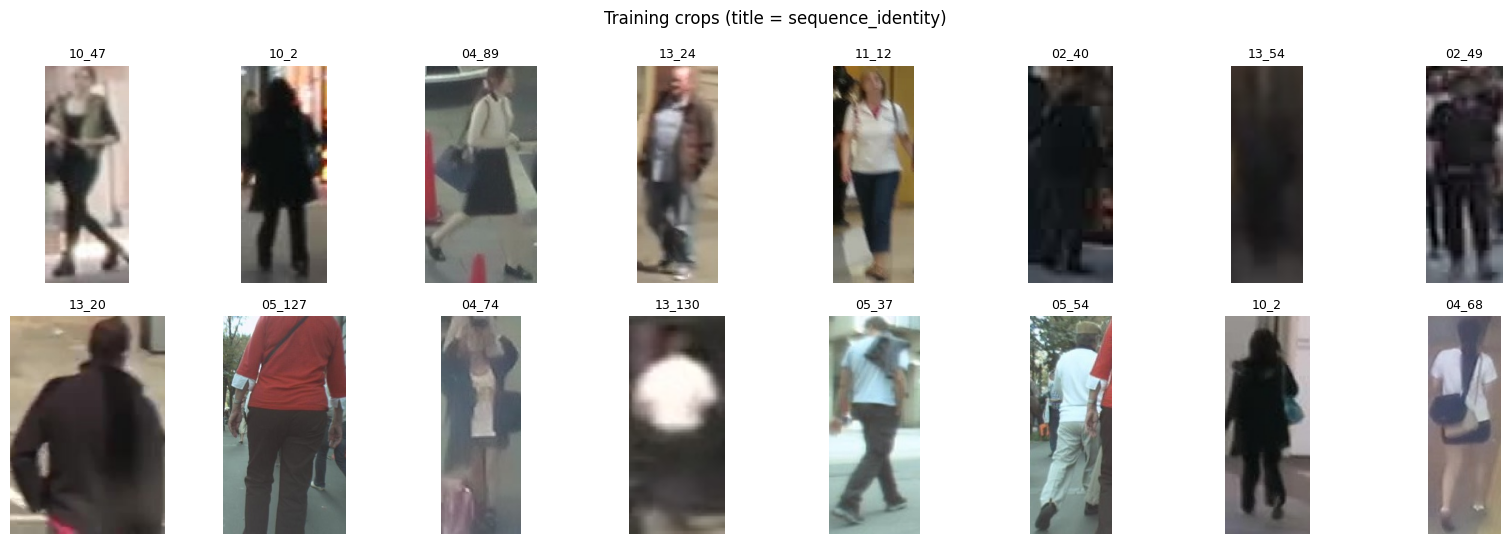

count    431.0
mean      22.9
std       20.5
min        1.0
25%        6.0
50%       15.0
75%       37.5
max       60.0
dtype: float64


In [ ]:
# 4. Look at the data: crops from different identities
fig, axes = plt.subplots(2, 8, figsize=(16, 5.5))
for ax, (_, r) in zip(axes.ravel(), train_df.sample(16, random_state=1).iterrows()):
    ax.imshow(Image.open(r.path)); ax.set_title(r.pid.replace('MOT16-', ''), fontsize=9); ax.axis('off')
plt.suptitle('Training crops (title = sequence_identity)'); plt.tight_layout(); plt.show()
print(train_df.groupby('pid').size().describe().round(1))

In [ ]:
# 5. Model, transforms, embedding extraction and ReID metrics
import torchvision.transforms as T
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
tf_train = T.Compose([T.Resize((IMG_H, IMG_W)), T.RandomHorizontalFlip(), T.Pad(10), T.RandomCrop((IMG_H, IMG_W)),
                      T.ColorJitter(0.2, 0.2, 0.2), T.ToTensor(), T.Normalize(MEAN, STD),
                      T.RandomErasing(p=0.5, scale=(0.02, 0.25), value=0)])      # random erasing simulates occlusion
tf_eval  = T.Compose([T.Resize((IMG_H, IMG_W)), T.ToTensor(), T.Normalize(MEAN, STD)])

class CropDS(torch.utils.data.Dataset):
    def __init__(self, paths, labels, tf): self.paths, self.labels, self.tf = list(paths), list(labels), tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i): return self.tf(Image.open(self.paths[i]).convert('RGB')), self.labels[i]

class ReIDNet(nn.Module):
    # ResNet-50, last stride 1 (finer feature map), global pooling, BNNeck, ID classifier
    def __init__(self, n_classes=0, pretrained=True):
        super().__init__()
        r = torchvision.models.resnet50(weights='IMAGENET1K_V2' if pretrained else None)
        r.layer4[0].conv2.stride = (1, 1); r.layer4[0].downsample[0].stride = (1, 1)
        self.backbone = nn.Sequential(r.conv1, r.bn1, r.relu, r.maxpool, r.layer1, r.layer2, r.layer3, r.layer4)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.bn = nn.BatchNorm1d(2048); self.bn.bias.requires_grad_(False)
        self.cls = nn.Linear(2048, n_classes, bias=False) if n_classes else None
    def forward(self, x):
        f = self.pool(self.backbone(x)).flatten(1)       # feature before BN: used by the triplet loss
        fb = self.bn(f)                                  # feature after BN: used by the ID loss and at test time
        return f, fb, (self.cls(fb) if (self.training and self.cls is not None) else None)

@torch.no_grad()
def embed_loader(model, loader, use_bn):
    model.eval(); out = []
    for imgs, _ in loader:
        with torch.autocast(dev, dtype=torch.float16, enabled=(dev == 'cuda')):
            f, fb, _ = model(imgs.to(dev))
        out.append(F.normalize((fb if use_bn else f).float(), dim=1).cpu())
    return torch.cat(out).numpy()

def embed_paths(model, paths, use_bn, bs=128):
    dl = torch.utils.data.DataLoader(CropDS(paths, [0] * len(paths), tf_eval), batch_size=bs, num_workers=2)
    return embed_loader(model, dl, use_bn)

def eval_reid(qf, gf, qp, gp, valid_mask=None):
    # mAP and CMC. valid_mask[i, j] = False removes gallery item j for query i (used for Market-1501 camera filtering).
    sim = qf @ gf.T; aps, cmc, n_valid = [], np.zeros(gf.shape[0]), 0
    for i in range(len(qf)):
        order = np.argsort(-sim[i])
        if valid_mask is not None: order = order[valid_mask[i][order]]
        m = (gp[order] == qp[i]).astype(int)
        if m.sum() == 0: continue
        n_valid += 1; cmc[np.argmax(m):] += 1
        aps.append((np.cumsum(m) / (np.arange(len(m)) + 1) * m).sum() / m.sum())
    c = cmc / n_valid
    return dict(mAP=float(np.mean(aps)), R1=float(c[0]), R5=float(c[4]), R10=float(c[9]), queries=n_valid)

In [ ]:
# 6. Validation protocol on MOT16-09: query = early crops of each person, gallery = late crops of all people
# A time gap separates query and gallery, so the test is not solved by near-identical neighbouring frames.
q_rows, g_rows = [], []
for pid, g in val_df.groupby('pid'):
    g = g.sort_values('frame')
    if len(g) < 6: continue
    n = len(g); q_rows.append(g.iloc[: int(n * 0.4)]); g_rows.append(g.iloc[int(n * 0.6):])    # middle 20% is dropped
q_df, g_df = pd.concat(q_rows).reset_index(drop=True), pd.concat(g_rows).reset_index(drop=True)
qp, gp = q_df.pid.values, g_df.pid.values
print('queries:', len(q_df), '| gallery:', len(g_df), '| identities:', q_df.pid.nunique())

def evaluate_model(model, use_bn):
    return eval_reid(embed_paths(model, q_df.path, use_bn), embed_paths(model, g_df.path, use_bn), qp, gp)

# Baseline: ImageNet ResNet-50, no ReID training
base_model = ReIDNet(n_classes=0, pretrained=True).to(dev)
res_base = evaluate_model(base_model, use_bn=False)
print('ImageNet baseline:', {k: round(v, 4) for k, v in res_base.items()})

queries: 257 | gallery: 275 | identities: 22
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 219MB/s]


ImageNet baseline: {'mAP': 0.4599, 'R1': 0.5331, 'R5': 0.786, 'R10': 0.8599, 'queries': 257}


In [ ]:
# 7. Train (checkpoint to Drive every epoch; re-running resumes automatically)
def batch_hard_triplet(feat, y, margin):
    d = torch.cdist(feat, feat); same = (y[:, None] == y[None]).float()
    d_ap = (d * same).max(1).values                    # hardest positive
    d_an = (d + 1e9 * same).min(1).values              # hardest negative
    return F.relu(d_ap - d_an + margin).mean()

class PKSampler(torch.utils.data.Sampler):
    def __init__(self, labels, P, K, iters):
        self.by = {}
        for i, l in enumerate(labels): self.by.setdefault(l, []).append(i)
        self.ids = [l for l, v in self.by.items() if len(v) >= 2]; self.P, self.K, self.iters = P, K, iters
    def __len__(self): return self.iters * self.P * self.K
    def __iter__(self):
        for _ in range(self.iters):
            for l in random.sample(self.ids, self.P):
                idx = self.by[l]
                yield from (random.sample(idx, self.K) if len(idx) >= self.K else random.choices(idx, k=self.K))

CKPT, BEST = BASE/'reid_ckpt.pt', BASE/'reid_best.pt'
model = ReIDNet(n_classes=len(label_map), pretrained=True).to(dev)
history = []
if RUN_TRAIN:
    loader = torch.utils.data.DataLoader(CropDS(train_df.path, train_df.label, tf_train), batch_size=P * K,
                                         sampler=PKSampler(train_df.label.tolist(), P, K, ITERS), num_workers=2, drop_last=True)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=LR, weight_decay=5e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    scaler = torch.amp.GradScaler('cuda', enabled=(dev == 'cuda')); start, best_map = 0, -1
    if CKPT.exists():
        ck = torch.load(CKPT, map_location=dev)
        model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt']); sched.load_state_dict(ck['sched'])
        start, history, best_map = ck['epoch'], ck['history'], ck['best_map']; print('Resumed from epoch', start)
    for ep in range(start, EPOCHS):
        model.train(); t0 = time.time(); tot = ce_s = tri_s = 0
        for imgs, y in loader:
            imgs, y = imgs.to(dev), y.to(dev)
            with torch.autocast(dev, dtype=torch.float16, enabled=(dev == 'cuda')):
                f, fb, logits = model(imgs)
            ce = F.cross_entropy(logits.float(), y, label_smoothing=0.1)
            tri = batch_hard_triplet(F.normalize(f.float(), dim=1), y, MARGIN)
            loss = ce + tri
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item(); ce_s += ce.item(); tri_s += tri.item()
        sched.step(); n = len(loader)
        r = evaluate_model(model, use_bn=True)
        history.append(dict(epoch=ep + 1, loss=tot / n, ce=ce_s / n, triplet=tri_s / n, val_mAP=r['mAP'], val_R1=r['R1']))
        print(f"epoch {ep+1}/{EPOCHS} | loss {tot/n:.3f} (ce {ce_s/n:.3f}, tri {tri_s/n:.3f}) | val mAP {r['mAP']:.3f} R1 {r['R1']:.3f} | {time.time()-t0:.0f}s")
        if r['mAP'] > best_map: best_map = r['mAP']; torch.save(model.state_dict(), BEST)
        torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                        epoch=ep + 1, history=history, best_map=best_map), CKPT)
model.load_state_dict(torch.load(BEST, map_location=dev)); model.eval()
print('loaded best model:', BEST)

epoch 1/12 | loss 3.827 (ce 3.606, tri 0.221) | val mAP 0.735 R1 0.872 | 23s
epoch 2/12 | loss 1.519 (ce 1.398, tri 0.121) | val mAP 0.745 R1 0.879 | 24s
epoch 3/12 | loss 1.243 (ce 1.160, tri 0.084) | val mAP 0.799 R1 0.911 | 24s
epoch 4/12 | loss 1.166 (ce 1.109, tri 0.058) | val mAP 0.815 R1 0.907 | 24s
epoch 5/12 | loss 1.115 (ce 1.070, tri 0.045) | val mAP 0.844 R1 0.922 | 23s
epoch 6/12 | loss 1.073 (ce 1.039, tri 0.034) | val mAP 0.814 R1 0.895 | 23s
epoch 7/12 | loss 1.053 (ce 1.027, tri 0.026) | val mAP 0.818 R1 0.922 | 23s
epoch 8/12 | loss 1.027 (ce 1.007, tri 0.020) | val mAP 0.796 R1 0.895 | 22s
epoch 9/12 | loss 1.011 (ce 0.996, tri 0.014) | val mAP 0.810 R1 0.911 | 24s
epoch 10/12 | loss 0.998 (ce 0.987, tri 0.011) | val mAP 0.800 R1 0.907 | 24s
epoch 11/12 | loss 0.994 (ce 0.984, tri 0.011) | val mAP 0.814 R1 0.922 | 23s
epoch 12/12 | loss 0.988 (ce 0.979, tri 0.009) | val mAP 0.791 R1 0.903 | 23s
loaded best model: /content/drive/MyDrive/MOT16_project/Backup/reid_best.

,mAP,R1,R5,R10
ImageNet ResNet-50 (baseline),0.4599,0.5331,0.7860,0.8599
"Trained (ID + triplet, BNNeck)",0.8444,0.9222,0.9416,0.9455


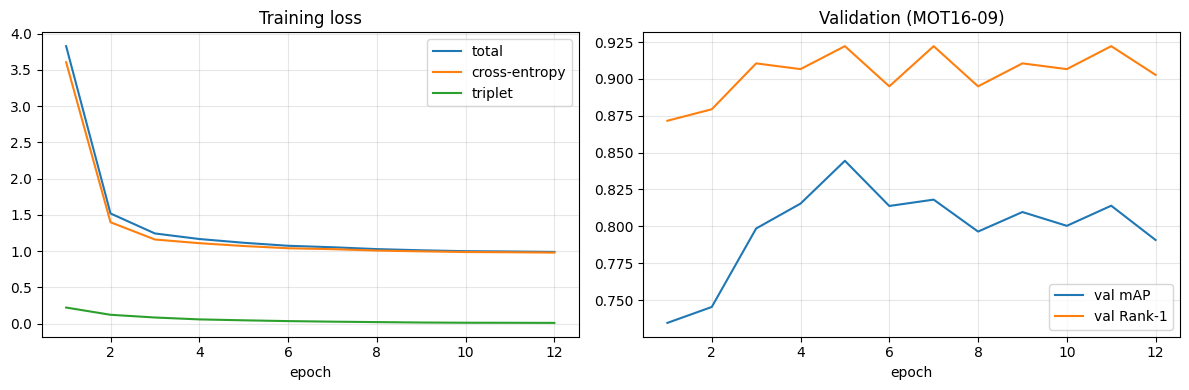

In [ ]:
# 8. Baseline vs trained model
res_ft = evaluate_model(model, use_bn=True)
cmp = pd.DataFrame({'ImageNet ResNet-50 (baseline)': res_base, 'Trained (ID + triplet, BNNeck)': res_ft}).T
cmp = cmp[['mAP', 'R1', 'R5', 'R10']].round(4); display(cmp)
cmp.to_csv(RESULTS/'reid_comparison.csv')
if history:
    h = pd.DataFrame(history); fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h.epoch, h.loss, label='total'); ax[0].plot(h.epoch, h.ce, label='cross-entropy'); ax[0].plot(h.epoch, h.triplet, label='triplet')
    ax[0].set_title('Training loss'); ax[0].legend()
    ax[1].plot(h.epoch, h.val_mAP, label='val mAP'); ax[1].plot(h.epoch, h.val_R1, label='val Rank-1'); ax[1].set_title(f'Validation ({SEQ})'); ax[1].legend()
    for a in ax: a.set_xlabel('epoch'); a.grid(alpha=.3)
    plt.tight_layout(); plt.savefig(RESULTS/'reid_training_curves.png', dpi=130); plt.show()

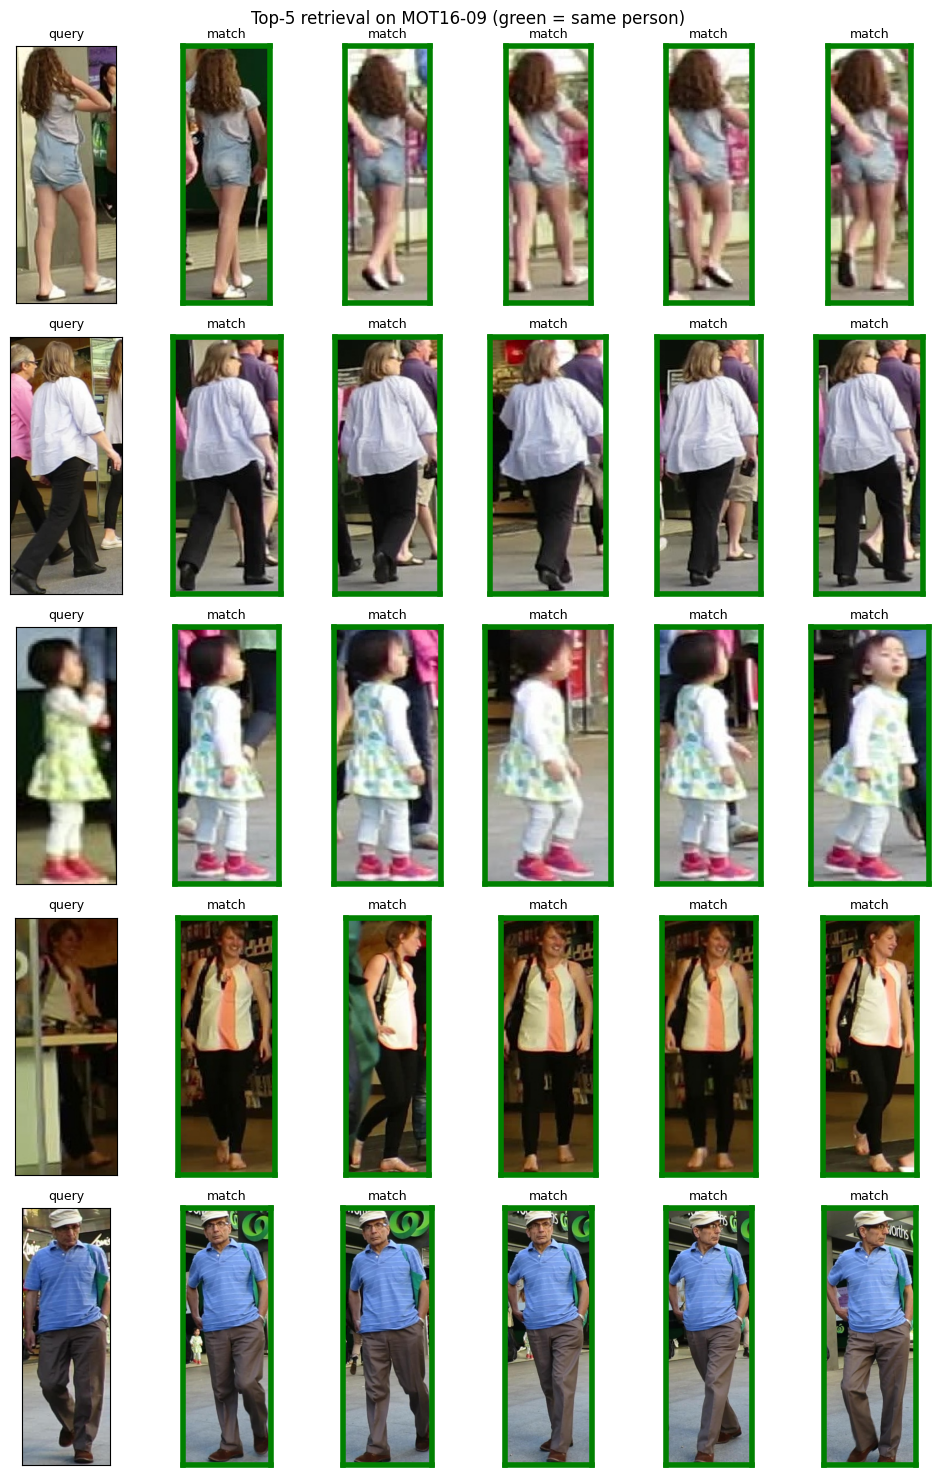

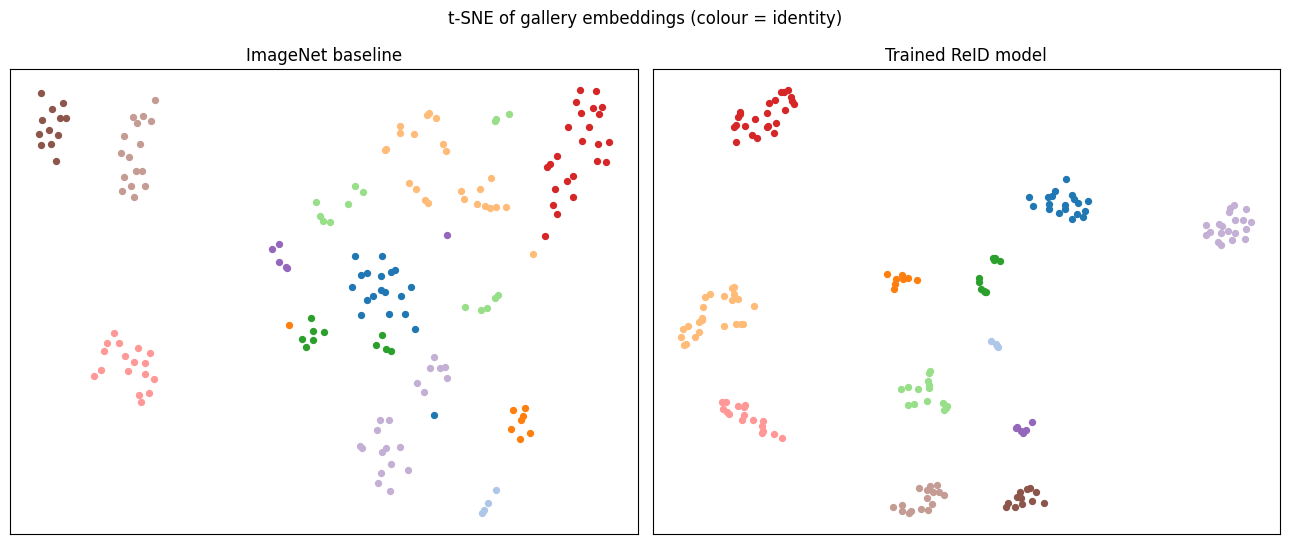

In [ ]:
# 9. Retrieval examples (top-5) and embedding space (t-SNE)
qf, gf = embed_paths(model, q_df.path, True), embed_paths(model, g_df.path, True)
rng = np.random.RandomState(3); picks = rng.choice(len(q_df), 5, replace=False)
fig, axes = plt.subplots(5, 6, figsize=(10, 15))
for row, qi in zip(axes, picks):
    order = np.argsort(-(qf[qi] @ gf.T))[:5]
    row[0].imshow(Image.open(q_df.path[qi])); row[0].set_title('query', fontsize=9)
    for ax, gi in zip(row[1:], order):
        ax.imshow(Image.open(g_df.path[gi])); ok = gp[gi] == qp[qi]
        for s in ax.spines.values(): s.set_edgecolor('green' if ok else 'red'); s.set_linewidth(4)
        ax.set_title('match' if ok else 'wrong', fontsize=9)
    for ax in row: ax.set_xticks([]); ax.set_yticks([])
plt.suptitle('Top-5 retrieval on MOT16-09 (green = same person)'); plt.tight_layout()
plt.savefig(RESULTS/'reid_top5_matches.png', dpi=130); plt.show()

from sklearn.manifold import TSNE
ids = rng.choice(sorted(set(qp)), 12, replace=False); sel = np.isin(gp, ids)
bf = embed_paths(base_model, g_df.path[sel], False)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, feats, title in [(axes[0], bf, 'ImageNet baseline'), (axes[1], gf[sel], 'Trained ReID model')]:
    xy = TSNE(n_components=2, perplexity=20, init='pca', random_state=0).fit_transform(feats)
    for i, pid in enumerate(ids):
        m = gp[sel] == pid; ax.scatter(xy[m, 0], xy[m, 1], s=18, color=plt.cm.tab20(i % 20))
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle('t-SNE of gallery embeddings (colour = identity)'); plt.tight_layout()
plt.savefig(RESULTS/'reid_tsne.png', dpi=130); plt.show()

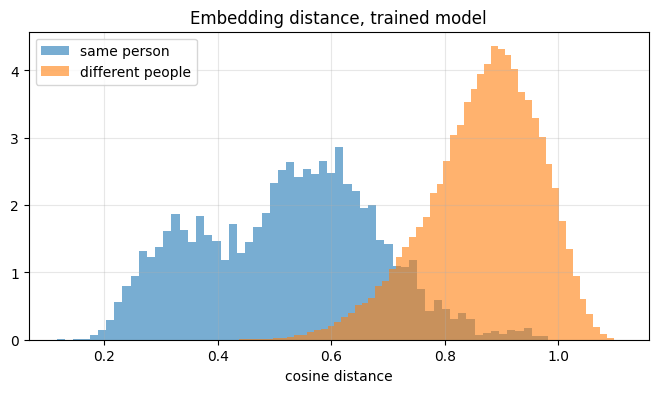

same person   : median 0.534 | 90th pct 0.716
different     : median 0.879 | 10th pct 0.733


In [ ]:
# 10. Distance distributions: how large is the cosine distance for the same person vs different people?
# These numbers are used to choose the split and merge thresholds in the tracking repair below.
D = 1 - qf @ gf.T; same = (qp[:, None] == gp[None])
d_same, d_diff = D[same], D[~same]
plt.figure(figsize=(8, 4)); plt.hist(d_same, 60, alpha=.6, density=True, label='same person'); plt.hist(d_diff, 60, alpha=.6, density=True, label='different people')
plt.xlabel('cosine distance'); plt.legend(); plt.title('Embedding distance, trained model'); plt.grid(alpha=.3)
plt.savefig(RESULTS/'reid_distance_hist.png', dpi=130); plt.show()
print('same person   : median %.3f | 90th pct %.3f' % (np.median(d_same), np.percentile(d_same, 90)))
print('different     : median %.3f | 10th pct %.3f' % (np.median(d_diff), np.percentile(d_diff, 10)))

In [ ]:
# 11. (Optional) Cross-domain check on Market-1501. Skipped if the dataset is not on Drive.
# Place the unzipped folder 'Market-1501-v15.09.15' in BASE. Expect a lower score than on MOT16: our model is trained on MOT16 only.
import zipfile
from pathlib import Path

zip_source = Path('/content/drive/MyDrive/MOT16_project/Market-1501-v15.09.15.zip')
extract_destination = Path('/content')

print("Extracting Market-1501...")
with zipfile.ZipFile(zip_source, 'r') as zip_ref:
    zip_ref.extractall(extract_destination)

MARKET = Path('/content/Market-1501-v15.09.15')
if not MARKET.exists():
    print('Market-1501 not found - skipped (optional).')
else:
    def market_list(d):
        files = sorted(d.glob('*.jpg')); pid = np.array([int(f.name.split('_')[0]) for f in files]); cam = np.array([int(f.name.split('_')[1][1]) for f in files])
        return files, pid, cam
    qfs, qpid, qcam = market_list(MARKET/'query'); gfs, gpid, gcam = market_list(MARKET/'bounding_box_test')
    mask = ~((gpid[None] == qpid[:, None]) & (gcam[None] == qcam[:, None])) & (gpid[None] != -1)     # remove same-camera and junk images
    out = {}
    for name, m, ub in [('ImageNet baseline', base_model, False), ('Trained on MOT16', model, True)]:
        out[name] = eval_reid(embed_paths(m, qfs, ub), embed_paths(m, gfs, ub), qpid, gpid, valid_mask=mask)
    mk = pd.DataFrame(out).T[['mAP', 'R1', 'R5', 'R10']].round(4); display(mk); mk.to_csv(RESULTS/'reid_market1501.csv')

Extracting Market-1501...


,mAP,R1,R5,R10
ImageNet baseline,0.0386,0.1170,0.2426,0.3091
Trained on MOT16,0.1552,0.3723,0.5499,0.6351


In [ ]:
# 12. TrackEval (same setup as Notebook 04) and evaluation helpers
!rm -rf /content/TrackEval && git clone -q https://github.com/JonathonLuiten/TrackEval /content/TrackEval
!find /content/TrackEval -name "*.py" -exec sed -i -E 's/np\.(float|int|bool)\b/\1/g' {} +
TE_ROOT = Path('/content/trackeval_data'); TE_GT, TE_TRACKERS = TE_ROOT/'gt', TE_ROOT/'trackers'
shutil.rmtree(TE_ROOT, ignore_errors=True); (TE_GT/SEQ/'gt').mkdir(parents=True); TE_TRACKERS.mkdir(parents=True)
shutil.copy(SEQ_DIR/'gt'/'gt.txt', TE_GT/SEQ/'gt'/'gt.txt'); shutil.copy(SEQ_DIR/'seqinfo.ini', TE_GT/SEQ/'seqinfo.ini')

def run_trackeval():
    names = sorted(p.name for p in TE_TRACKERS.iterdir() if p.is_dir())
    cmd = [sys.executable, 'scripts/run_mot_challenge.py', '--BENCHMARK', 'MOT16', '--SPLIT_TO_EVAL', 'train', '--SKIP_SPLIT_FOL', 'True',
           '--GT_FOLDER', str(TE_GT), '--TRACKERS_FOLDER', str(TE_TRACKERS), '--SEQ_INFO', SEQ,
           '--TRACKERS_TO_EVAL', *names, '--METRICS', 'HOTA', 'CLEAR', 'Identity', '--USE_PARALLEL', 'False',
           '--PRINT_CONFIG', 'False', '--PRINT_RESULTS', 'False', '--OUTPUT_SUMMARY', 'True', '--OUTPUT_DETAILED', 'False', '--PLOT_CURVES', 'False']
    res = subprocess.run(cmd, cwd='/content/TrackEval', capture_output=True, text=True)
    if res.returncode != 0:
        print(res.stdout[-3000:]); print(res.stderr[-3000:]); raise RuntimeError('TrackEval failed')
    return names

COLS = ['HOTA', 'DetA', 'AssA', 'MOTA', 'IDF1', 'IDSW', 'Frag']
def collect_results(names):
    rows = []
    for n in names:
        s = pd.read_csv(TE_TRACKERS/n/'pedestrian_summary.txt', sep=r'\s+')
        t = pd.read_csv(TE_TRACKERS/n/'data'/f'{SEQ}.txt', header=None)
        rows.append({'run': n, **{c: float(s.iloc[0][c]) for c in COLS if c in s.columns}, 'pred_ids': t[1].nunique()})
    return pd.DataFrame(rows).set_index('run')

TR_COLS = ['frame', 'id', 'x', 'y', 'w', 'h', 'conf', 'a', 'b', 'c']
def write_tracks(df, name):
    out = TE_TRACKERS/name/'data'/f'{SEQ}.txt'; out.parent.mkdir(parents=True, exist_ok=True)
    lines = [f'{int(r.frame)},{int(r.id)},{r.x:.2f},{r.y:.2f},{r.w:.2f},{r.h:.2f},{r.conf:.4f},-1,-1,-1' for r in df.itertuples()]
    out.write_text('\n'.join(lines) + '\n')

gt_ids = pd.read_csv(SEQ_DIR/'gt'/'gt.txt', header=None, names=GT_COLS).query('cls == 1 and conf == 1')['id'].nunique()
print('Ground-truth identities in', SEQ, ':', gt_ids)

Ground-truth identities in MOT16-09 : 25


In [ ]:
# 13. Load the tracker output from Notebook 04 and compute one embedding per box
SRC_RUN = 'E2_finetuned_botsort'          # tracker output to repair; change to another run name if needed
TRK_DIR = BASE/'results'/'tracks_txt'/SRC_RUN
src = next((p for p in [TRK_DIR/f'{SEQ}.txt', TRK_DIR/'data'/f'{SEQ}.txt'] if p.exists()), None)
assert src is not None, ("Tracker output not on Drive. In Notebook 04 (runtime still open) run:\n"
                      "  shutil.copytree(TE_TRACKERS, RESULTS/'tracks_txt', dirs_exist_ok=True)\n"
                      "or re-run Notebook 04 cells 1-6 with the updated notebook.")
trk = pd.read_csv(src, header=None, names=TR_COLS).sort_values(['frame', 'id']).reset_index(drop=True)
print('boxes:', len(trk), '| tracks:', trk.id.nunique())

@torch.no_grad()
def embed_boxes(model, trk, bs=256):
    model.eval(); embs = np.zeros((len(trk), 2048), dtype=np.float32); buf, idx = [], []
    def flush():
        if not buf: return
        x = torch.stack(buf).to(dev)
        with torch.autocast(dev, dtype=torch.float16, enabled=(dev == 'cuda')):
            _, fb, _ = model(x)
        embs[idx] = F.normalize(fb.float(), dim=1).cpu().numpy(); buf.clear(); idx.clear()
    for f, g in tqdm(trk.groupby('frame'), desc='embedding boxes'):
        img = cv2.cvtColor(cv2.imread(str(IMG_DIR/f'{int(f):06d}.jpg')), cv2.COLOR_BGR2RGB); H, W = img.shape[:2]
        for i, r in zip(g.index, g.itertuples()):
            x1, y1 = max(int(r.x), 0), max(int(r.y), 0); x2, y2 = min(int(r.x + r.w), W), min(int(r.y + r.h), H)
            if x2 - x1 < 4 or y2 - y1 < 4: continue
            buf.append(tf_eval(Image.fromarray(img[y1:y2, x1:x2]))); idx.append(i)
            if len(buf) >= bs: flush()
    flush(); return embs

EMB = embed_boxes(model, trk)
print('embeddings:', EMB.shape)

boxes: 4777 | tracks: 72


embedding boxes:   0%|          | 0/525 [00:00<?, ?it/s]

embeddings: (4777, 2048)


In [ ]:
# 14. Split and merge
def cos_dist(a, b): return 1 - float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-9))

def split_tracks(trk, emb, t_split, win=8):
    # cut a track where the appearance of the previous `win` boxes differs from the next `win` boxes
    trk = trk.copy(); trk['tl'] = trk['id']; next_id = int(trk['id'].max()) + 1
    for tid, g in trk.groupby('id'):
        idx = g.sort_values('frame').index.values
        if len(idx) < 2 * win: continue
        E = emb[idx]; i = win; cuts = []
        while i <= len(idx) - win:
            if cos_dist(E[i - win:i].mean(0), E[i:i + win].mean(0)) > t_split:
                cuts.append(i); i += win
            else: i += 1
        for c in cuts:
            trk.loc[idx[c:], 'tl'] = next_id; next_id += 1
    return trk

def merge_tracks(trk, emb, t_merge, max_gap=150, max_speed=0.06):
    # greedy agglomerative merge of non-overlapping tracklets; max_speed is in body heights per frame
    groups = []
    for tl, g in trk.groupby('tl'):
        g = g.sort_values('frame'); e = emb[g.index.values].mean(0); e /= (np.linalg.norm(e) + 1e-9)
        groups.append(dict(members=[tl], start=int(g.frame.iloc[0]), end=int(g.frame.iloc[-1]), emb=e, n=len(g),
                           first=g.iloc[0][['x', 'y', 'w', 'h']].values.astype(float), last=g.iloc[-1][['x', 'y', 'w', 'h']].values.astype(float)))
    while True:
        best = None
        for a in groups:
            for b in groups:
                if a is b or a['end'] >= b['start']: continue            # a must finish before b starts (no overlap, no interleaving)
                gap = b['start'] - a['end']
                if gap > max_gap: continue
                ca = a['last'][:2] + a['last'][2:] / 2; cb = b['first'][:2] + b['first'][2:] / 2
                h = (a['last'][3] + b['first'][3]) / 2
                if np.linalg.norm(ca - cb) / h > 1.0 + max_speed * gap: continue       # position not plausible after the gap
                d = cos_dist(a['emb'], b['emb'])
                if d < t_merge and (best is None or d < best[0]): best = (d, a, b)
        if best is None: break
        _, a, b = best
        a['emb'] = (a['emb'] * a['n'] + b['emb'] * b['n']); a['emb'] /= (np.linalg.norm(a['emb']) + 1e-9)
        a['n'] += b['n']; a['end'] = b['end']; a['last'] = b['last']; a['members'] += b['members']; groups.remove(b)
    new_id = {tl: k + 1 for k, g in enumerate(groups) for tl in g['members']}
    out = trk.copy(); out['id'] = out['tl'].map(new_id); return out.drop(columns='tl')

def repair(trk, emb, t_split, t_merge):
    t = split_tracks(trk, emb, t_split) if t_split is not None else trk.assign(tl=trk['id'])
    return merge_tracks(t, emb, t_merge)

In [ ]:
# 15. Grid of split / merge thresholds, evaluated with TrackEval
write_tracks(trk, 'R0_baseline_' + SRC_RUN)                       # the original tracker output, for comparison
GRID = [(ts, tm) for ts in [None, 0.5, 0.4] for tm in [0.25, 0.35, 0.45]]
for ts, tm in GRID:
    write_tracks(repair(trk, EMB, ts, tm), f'R_split{ts}_merge{tm}')
names = run_trackeval()
repair_table = collect_results(names).sort_values('IDF1', ascending=False)
display(repair_table.round(3)); repair_table.round(4).to_csv(RESULTS/'reid_repair_results.csv')
print('Ground-truth identities:', gt_ids)

,HOTA,DetA,AssA,MOTA,IDF1,IDSW,Frag,pred_ids
run,,,,,,,,
R_split0.5_merge0.35,55.303,60.251,50.888,68.347,68.037,56.0,96.0,72
R_split0.5_merge0.45,54.761,60.270,49.870,68.347,67.955,56.0,96.0,61
R_split0.4_merge0.45,54.137,60.614,48.493,68.005,66.755,74.0,95.0,71
R_split0.4_merge0.35,54.297,60.615,48.787,67.986,65.351,75.0,95.0,90
R_splitNone_merge0.35,52.028,60.254,45.033,68.613,62.584,42.0,95.0,58
R_splitNone_merge0.45,51.665,60.207,44.441,68.613,61.770,42.0,95.0,50
R_split0.5_merge0.25,51.413,60.398,43.922,68.252,60.407,61.0,96.0,85
R_split0.4_merge0.25,51.133,60.569,43.343,67.967,59.837,76.0,95.0,103
R_splitNone_merge0.25,48.610,60.334,39.298,68.537,55.890,46.0,95.0,65


Ground-truth identities: 25


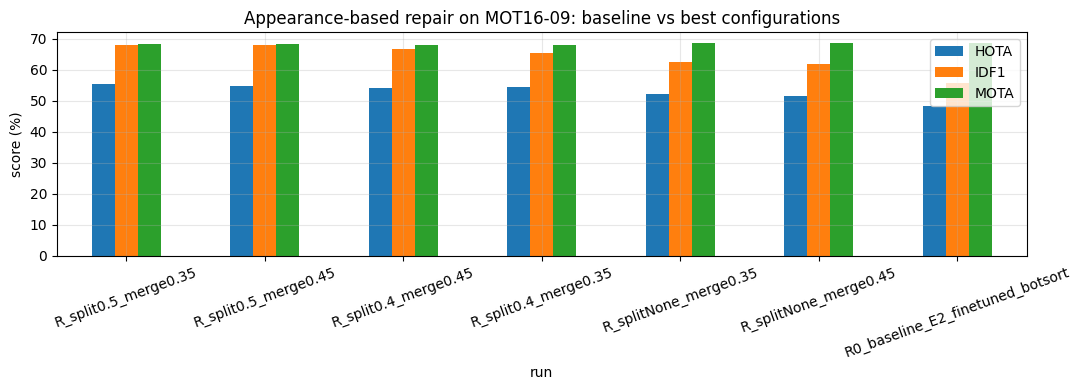

Best by IDF1: R_split0.5_merge0.35
ID switches: 46 -> 56 | IDF1: 55.65 -> 68.04 | HOTA: 48.40 -> 55.30 | track IDs: 72 -> 72


PosixPath('/content/drive/MyDrive/MOT16_project/Backup/results/tracks_txt/REPAIRED_E2_finetuned_botsort/MOT16-09.txt')

In [ ]:
# 16. Plot and save the best repaired tracks (they can be used by Notebook 06)
base_row = repair_table.loc['R0_baseline_' + SRC_RUN]; best_name = repair_table.index[0]
top = repair_table.head(6).copy(); top.loc['R0_baseline_' + SRC_RUN] = base_row; top = top[~top.index.duplicated()]
ax = top[['HOTA', 'IDF1', 'MOTA']].plot.bar(figsize=(11, 4), rot=20); ax.set_ylabel('score (%)'); ax.grid(alpha=.3)
ax.set_title(f'Appearance-based repair on {SEQ}: baseline vs best configurations'); plt.tight_layout()
plt.savefig(RESULTS/'reid_repair_bars.png', dpi=130); plt.show()
print('Best by IDF1:', best_name)
print('ID switches: %d -> %d | IDF1: %.2f -> %.2f | HOTA: %.2f -> %.2f | track IDs: %d -> %d' % (
    base_row.IDSW, repair_table.loc[best_name].IDSW, base_row.IDF1, repair_table.loc[best_name].IDF1,
    base_row.HOTA, repair_table.loc[best_name].HOTA, base_row.pred_ids, repair_table.loc[best_name].pred_ids))
(RESULTS/'tracks_txt'/('REPAIRED_' + SRC_RUN)).mkdir(parents=True, exist_ok=True)
shutil.copy(TE_TRACKERS/best_name/'data'/f'{SEQ}.txt', RESULTS/'tracks_txt'/('REPAIRED_' + SRC_RUN)/f'{SEQ}.txt')

## Findings and Discussion: ReID and Tracking Repair

### 10. ReID model quality

The trained ReID model improves strongly over the ImageNet baseline on the MOT16-09 retrieval test.

| Model | mAP | Rank-1 | Rank-5 | Rank-10 |
|---|---|---|---|---|
| ImageNet ResNet-50 (baseline) | 0.460 | 0.533 | 0.786 | 0.860 |
| Trained (ID loss + triplet loss, BNNeck) | 0.844 | 0.922 | 0.942 | 0.946 |

The validation mAP reached its highest value at epoch 5 and then varied between 0.79 and 0.82, while the training loss continued to decrease. This suggests mild overfitting, because the model is trained on only six sequences. The saved model was selected by the validation score of the same sequence, so the final value may be slightly optimistic.

### 11. Effect on tracking

We used the embeddings to split tracks that contain two people and to merge tracks that belong to one person. The table compares the baseline (E2, fine-tuned detector with BoT-SORT) with selected settings.

| Setting | HOTA | AssA | IDF1 | MOTA | ID switches | Track IDs |
|---|---|---|---|---|---|---|
| Baseline | 48.4 | 39.0 | 55.6 | 68.5 | 46 | 72 |
| Merge only (0.35) | 52.0 | 45.0 | 62.6 | 68.6 | 42 | 58 |
| Split 0.5 + merge 0.35 (best) | 55.3 | 50.9 | 68.0 | 68.3 | 56 | 72 |
| Split 0.4 + merge 0.35 | 54.3 | 48.8 | 65.4 | 68.0 | 75 | 90 |

The ground truth has 25 identities.

**Observations**
1. The repair improves association quality: AssA increases by 11.9 points and IDF1 by 12.4 points in the best setting.
2. Detection metrics do not change (DetA about 60.3, MOTA about 68.5). This is expected, because the repair does not add or remove detections.
3. Splitting gives the largest improvement, but it also increases the number of ID switches (from 46 to 56). A probable reason is that every cut creates a new ID, and a cut placed at a wrong frame is counted as an additional switch. The gain in AssA and IDF1 shows that removing long wrong-identity segments is worth more than this cost. This explanation needs a direct check.
4. Settings that are too strict (merge 0.25) change little, and settings that cut too easily (split 0.4) increase ID switches and lower the scores.
5. The fragmentation count stays at 95 to 96. Missing detections, mostly of heavily occluded people (Notebook 04), are not repaired by appearance.

### 12. Limitations

- The thresholds and the ReID model were selected on MOT16-09, which is also the sequence used for the final scores. The reported improvement may be optimistic. A second held-out sequence is needed for a fair test.
- Only a few threshold values were tested. Split values above 0.5 were not tested.
- The repair works offline, because it uses the whole video.